In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from pathlib import Path
from PIL import Image

In [2]:
train_files = list(Path("../data/training").glob("*/*"))

In [10]:
train_dataset, validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/training",
    image_size=(224, 224),
    seed = 42,
    validation_split = 0.2,
    subset = "both",
    batch_size=32,
    label_mode="binary"
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/testing",
    image_size=(224, 224),
    shuffle=False,
    batch_size=32,
    label_mode="binary"
)

Found 2392 files belonging to 2 classes.
Using 1914 files for training.
Using 478 files for validation.
Found 597 files belonging to 2 classes.


In [ ]:
for images, labels in train_dataset.take(1):
    print("Image batch:", images.shape)
    print("Label batch:", labels.shape)

ValueError: too many values to unpack (expected 2)

In [11]:
from keras.models import Sequential
model = Sequential()
from tensorflow.keras.layers import Input, Flatten, Dense

model.add(Input(shape=(224, 224, 3)))
model.add(Flatten())
model.add(Dense(10, activation='relu'))
model.add(Dense(10, activation='relu'))
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer='adam',
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=3
)
test_loss, test_accuracy = model.evaluate(test_dataset)


Epoch 1/3


c:\Users\msafw\anaconda3\lib\site-packages\keras\src\losses\losses.py:33: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(None, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._fn_kwargs)


60/60 ━━━━━━━━━━━━━━━━━━━━ 37s 521ms/step - accuracy: 0.4896 - loss: 0.0000e+00 - val_accuracy: 0.4749 - val_loss: 0.0000e+00
Epoch 2/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 33s 559ms/step - accuracy: 0.4885 - loss: 0.0000e+00 - val_accuracy: 0.4749 - val_loss: 0.0000e+00
Epoch 3/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 37s 488ms/step - accuracy: 0.4885 - loss: 0.0000e+00 - val_accuracy: 0.4749 - val_loss: 0.0000e+00
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 307ms/step - accuracy: 0.4858 - loss: 0.0000e+00


In [ ]:
from keras.models import Sequential
from tensorflow.keras.layers import  Input, Conv2D, MaxPool2D, Flatten, Dense, BatchNormalization

model = Sequential()
model.add(Input(shape=(224, 224, 3)))

model.add(Conv2D(10, kernel_size=3, 
                 activation='relu', 
                 strides=1,
                 padding='same'))
model.add(BatchNormalization())
model.add(MaxPool2D(2))
model.add(Conv2D(10, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Conv2D(10, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Flatten())
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer='adam',
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=3
)
test_loss, test_accuracy = model.evaluate(test_dataset)

Epoch 1/3


c:\Users\msafw\anaconda3\lib\site-packages\keras\src\losses\losses.py:33: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(None, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._fn_kwargs)


60/60 ━━━━━━━━━━━━━━━━━━━━ 68s 932ms/step - accuracy: 0.4890 - loss: 0.0000e+00 - val_accuracy: 0.4749 - val_loss: 0.0000e+00
Epoch 2/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 53s 871ms/step - accuracy: 0.4885 - loss: 0.0000e+00 - val_accuracy: 0.4749 - val_loss: 0.0000e+00
Epoch 3/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.4885 - loss: 0.0000e+00 - val_accuracy: 0.4749 - val_loss: 0.0000e+00
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 312ms/step - accuracy: 0.4858 - loss: 0.0000e+00


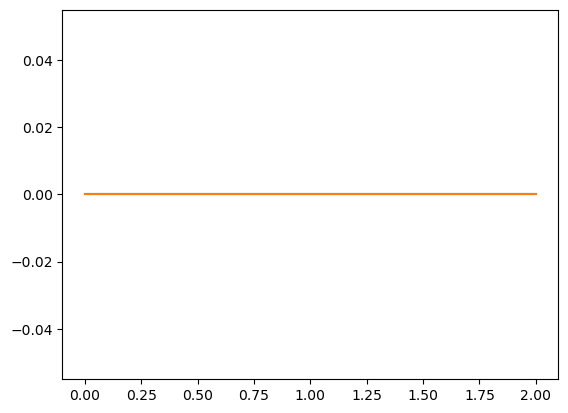

In [15]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.show()

In [ ]:
# Data augmentation mild setup
# the idea the images are too large therefore resizing required 

data_augmentation = tf.keras.Sequential([
    #tf.keras.layers.RandomFlip("horizontal"),
    #tf.keras.layers.RandomRotation(0.02),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(factor=0.1)
])


def load_small_image(file):
    with Image.open(file) as img:
        return np.array(
            img.convert("RGB").resize((224, 224)),
            dtype="float32"
        )
    
    

augmented_images = [
    data_augmentation(load_small_image(file), training=True)
    for file in train_files
]